# Week 3 · Part E — Written justification

This one-page justification is tied to a reproducible Part D design. The audit cell below verifies every reported cleaning count and parameter, then saves the primary 2×2 review figure and its unfiltered heart-rate-fault counterpart for the appendix. All records are synthetic and generated for CDB601220.

Rows loaded: 10,000; rows after heart-rate rule: 9,971
Ward variants: 12 -> 4 canonical wards; rows removed: 0
Dates parsed: {'ISO year-month-day': 3382, 'day-month-name-year': 3365, 'day/month/year': 3253}; unparsed: 0; rows removed: 0
BMI sentinel cells: 0 = 84, 999 = 402, total = 486; recoded to missing, not rows removed
BMI mean: 66.18 -> 27.35 kg/m²
Heart-rate faults >250 bpm: n = 29
Mean heart rate: 78.8331 -> 77.9843 bpm
Systolic range: 92–199 mmHg; Freedman–Diaconis: 29 bins, mean width 3.69 mmHg
  candidate bins=15: local peaks near [124.1, 159.8]
  candidate bins=29: local peaks near [112.3, 119.7, 160.3, 167.6]
  candidate bins=45: local peaks near [109.8, 117.0, 124.1, 128.9, 136.0, 143.1, 147.9, 155.0, 162.1, 166.9, 174.0]
Heatmap: 9 × 9, MAP excluded as derived; systolic/diastolic r = 0.889
LOS ward order by median: ['Day Surgery', 'General Medicine', 'Cardiology', 'Intensive Care']
LOS zero values retained: 2; maximum = 273.65 days
Saved: d:\7_Semester\data-visualization

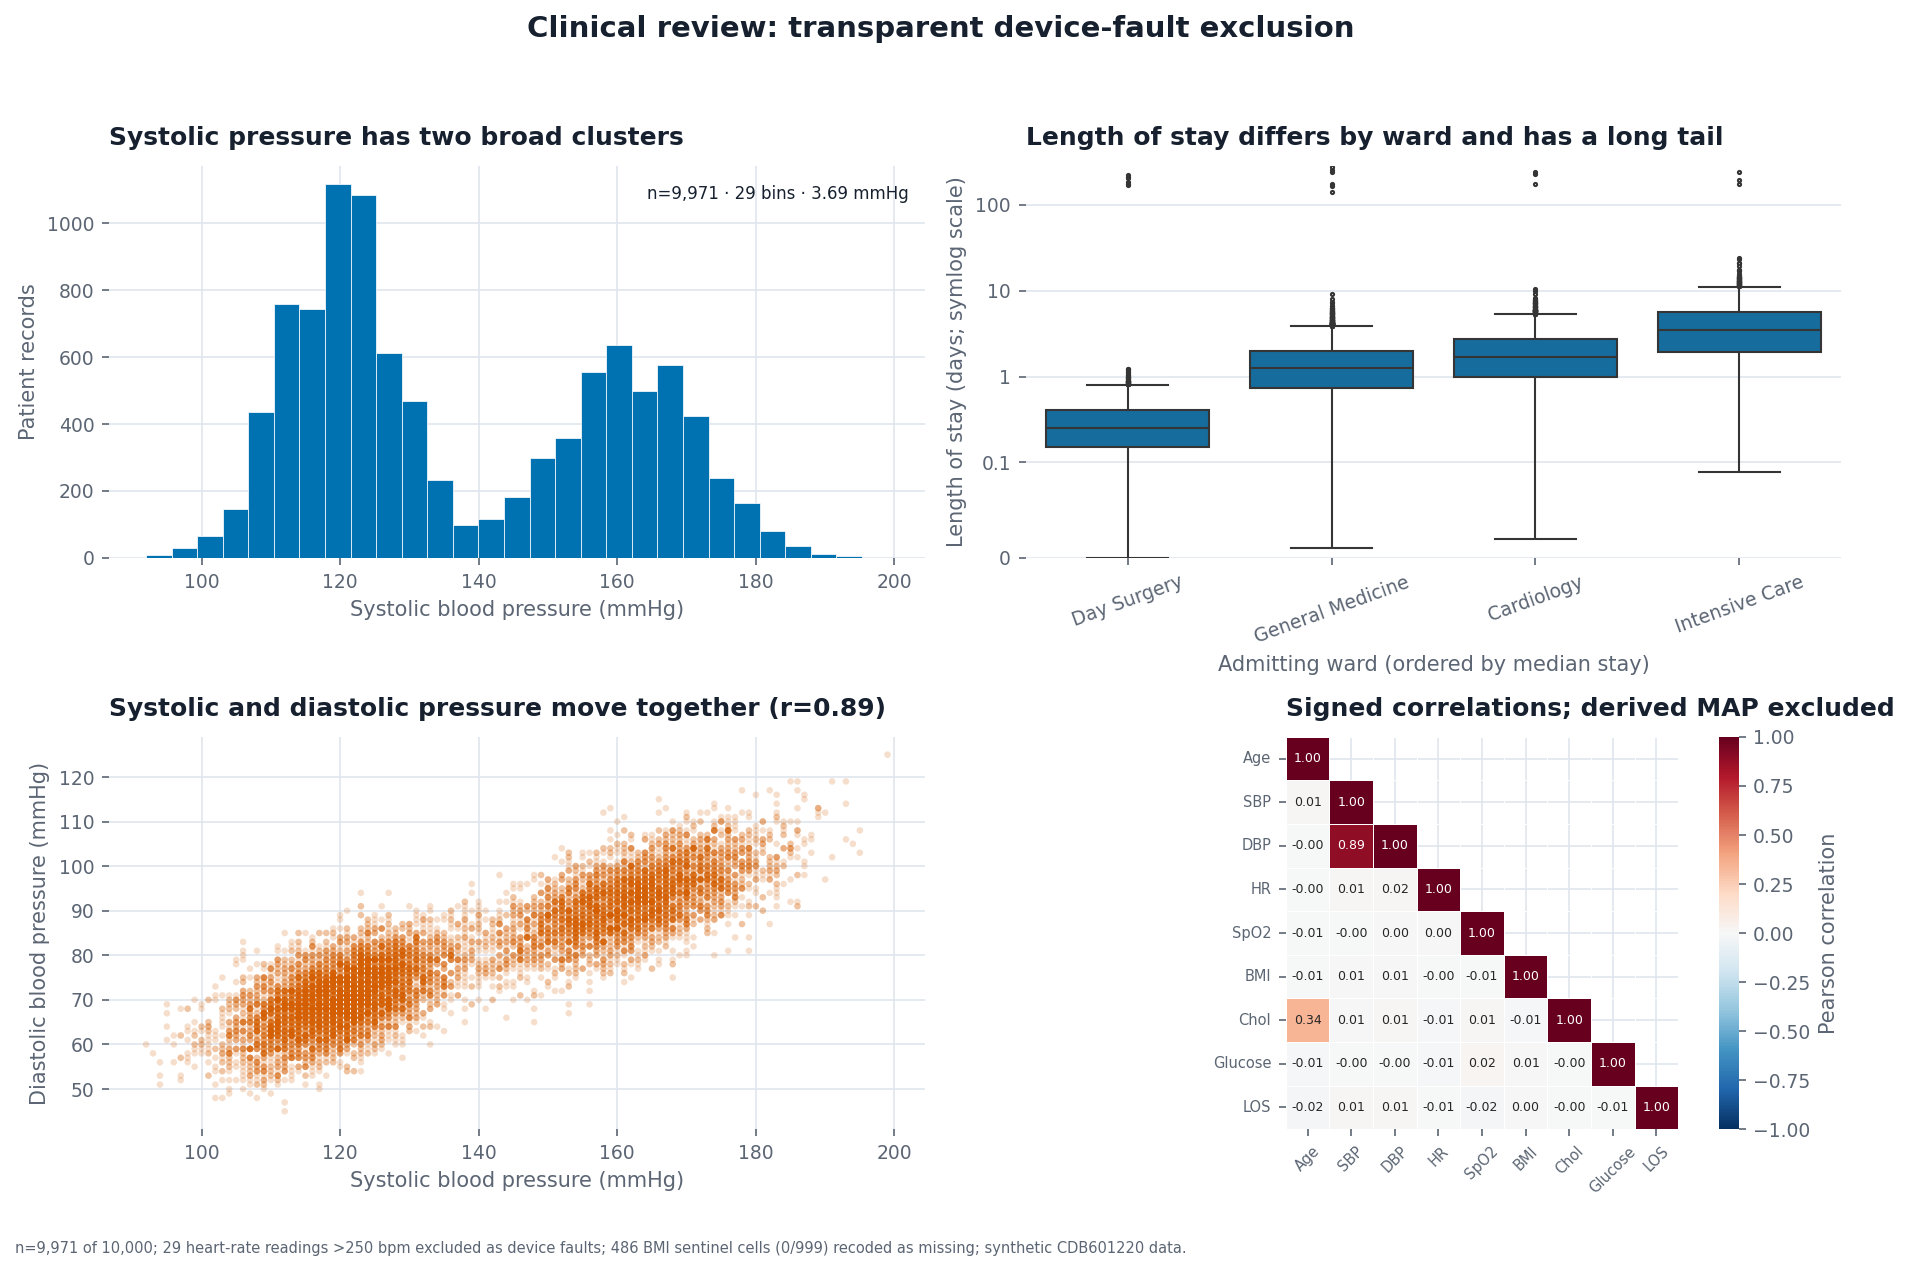

Saved: d:\7_Semester\data-visualization\week3\assignments\partD_figure_unfiltered_appendix.png


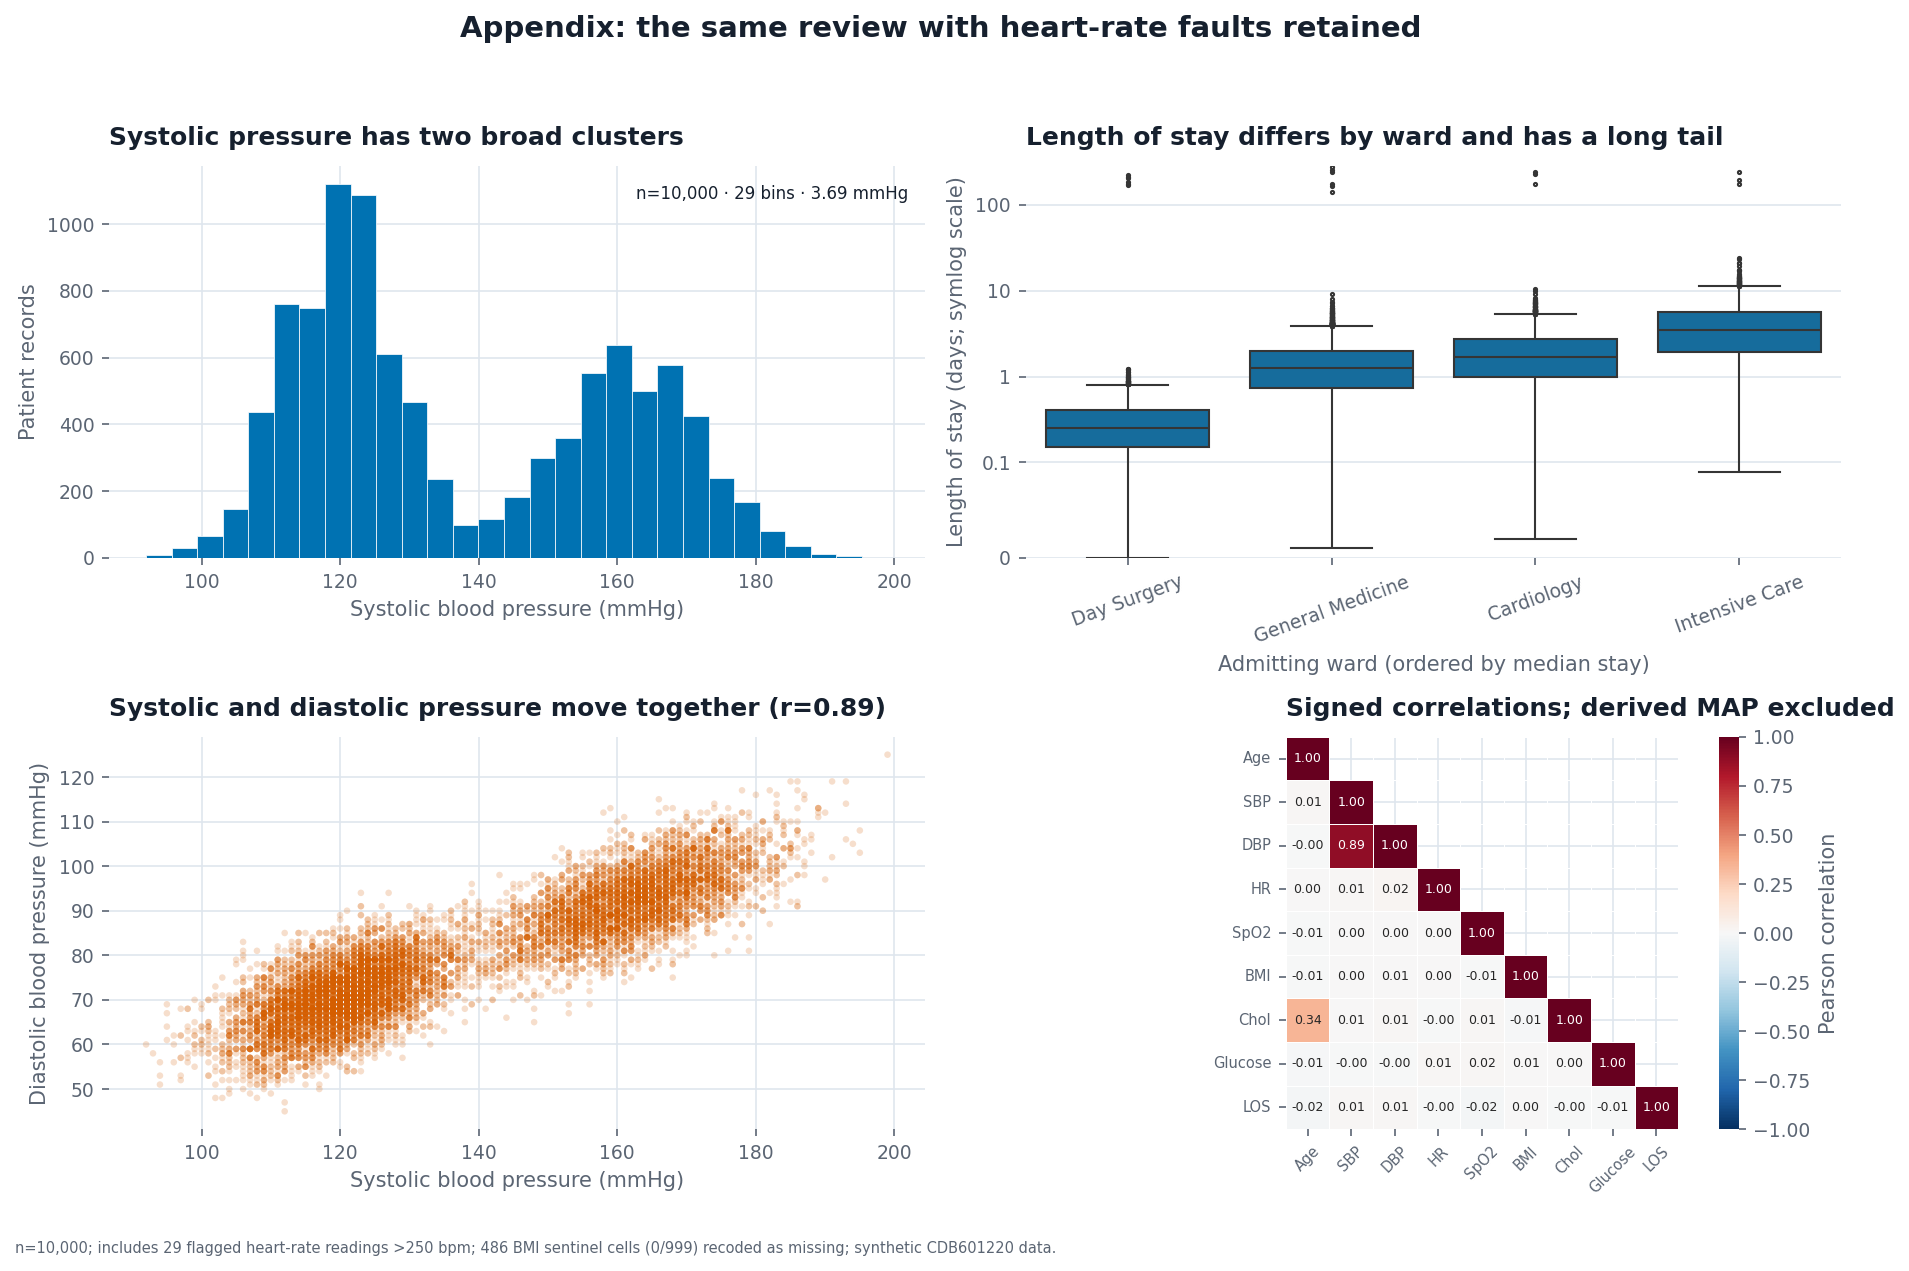

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

WEEK3_DIR = next(
    path for path in (Path.cwd(), Path.cwd() / "week3", Path.cwd().parent / "week3")
    if (path / "assignments" / "data" / "vitals_10k.csv").is_file()
)
ASSIGNMENTS_DIR = WEEK3_DIR / "assignments"
sys.path.insert(0, str(ASSIGNMENTS_DIR))
from vizlib import PALETTE, style_defaults

style_defaults()
raw = pd.read_csv(ASSIGNMENTS_DIR / "data" / "vitals_10k.csv")
rows_loaded = len(raw)

ward_map = {
    "general medicine": "General Medicine", "gen medicine": "General Medicine",
    "cardiology": "Cardiology", "cardio": "Cardiology",
    "day surgery": "Day Surgery", "day-surgery": "Day Surgery",
    "intensive care": "Intensive Care", "icu": "Intensive Care", "i.c.u": "Intensive Care",
}
cleaned = raw.copy()
cleaned["ward_clean"] = cleaned["ward"].str.strip().str.lower().map(ward_map)
assert cleaned["ward_clean"].nunique() == 4 and cleaned["ward_clean"].isna().sum() == 0

admit_formats = {
    "ISO year-month-day": "%Y-%m-%d",
    "day-month-name-year": "%d-%b-%Y",
    "day/month/year": "%d/%m/%Y",
}
admit_dt = pd.Series(pd.NaT, index=cleaned.index, dtype="datetime64[ns]")
format_counts = {}
for format_name, date_format in admit_formats.items():
    parsed = pd.to_datetime(cleaned["admit_date"], format=date_format, errors="coerce")
    format_counts[format_name] = int(parsed.notna().sum())
    admit_dt = admit_dt.fillna(parsed)
cleaned["admit_dt"] = admit_dt
assert cleaned["admit_dt"].isna().sum() == 0

bmi_sentinel_mask = cleaned["bmi"].isin([0, 999])
bmi_sentinel_count = int(bmi_sentinel_mask.sum())
bmi_zero_count = int((cleaned["bmi"] == 0).sum())
bmi_999_count = int((cleaned["bmi"] == 999).sum())
bmi_mean_before = float(cleaned["bmi"].mean())
cleaned.loc[bmi_sentinel_mask, "bmi"] = np.nan
bmi_mean_after = float(cleaned["bmi"].mean())

heart_rate_faults = cleaned["heart_rate"] > 250
heart_rate_fault_count = int(heart_rate_faults.sum())
heart_rate_mean_before = float(cleaned["heart_rate"].mean())
review = cleaned.loc[~heart_rate_faults].copy()
heart_rate_mean_after = float(review["heart_rate"].mean())

print(f"Rows loaded: {rows_loaded:,}; rows after heart-rate rule: {len(review):,}")
print(f"Ward variants: {raw['ward'].nunique()} -> {review['ward_clean'].nunique()} canonical wards; rows removed: 0")
print(f"Dates parsed: {format_counts}; unparsed: {int(cleaned['admit_dt'].isna().sum())}; rows removed: 0")
print(f"BMI sentinel cells: 0 = {bmi_zero_count}, 999 = {bmi_999_count}, total = {bmi_sentinel_count}; recoded to missing, not rows removed")
print(f"BMI mean: {bmi_mean_before:.2f} -> {bmi_mean_after:.2f} kg/m²")
print(f"Heart-rate faults >250 bpm: n = {heart_rate_fault_count}")
print(f"Mean heart rate: {heart_rate_mean_before:.4f} -> {heart_rate_mean_after:.4f} bpm")

systolic = review["systolic"].dropna()
fd_edges = np.histogram_bin_edges(systolic, bins="fd")
fd_bins = len(fd_edges) - 1
fd_width = float(np.diff(fd_edges).mean())
print(f"Systolic range: {systolic.min()}–{systolic.max()} mmHg; Freedman–Diaconis: {fd_bins} bins, mean width {fd_width:.2f} mmHg")
for candidate_bins in [15, fd_bins, 45]:
    counts, edges = np.histogram(systolic, bins=candidate_bins)
    centers = (edges[:-1] + edges[1:]) / 2
    peaks = [round(float(centers[i]), 1) for i in range(1, len(counts) - 1)
             if counts[i] >= counts[i - 1] and counts[i] >= counts[i + 1] and counts[i] >= 0.1 * counts.max()]
    print(f"  candidate bins={candidate_bins}: local peaks near {peaks}")

heatmap_columns = [
    "age", "systolic", "diastolic", "heart_rate", "spo2", "bmi",
    "chol_mmol_l", "glucose_mmol_l", "los_days",
]
correlation = review[heatmap_columns].corr(method="pearson")
scatter_r = float(correlation.loc["systolic", "diastolic"])
ward_order = review.groupby("ward_clean")["los_days"].median().sort_values().index.tolist()
print(f"Heatmap: {correlation.shape[0]} × {correlation.shape[1]}, MAP excluded as derived; systolic/diastolic r = {scatter_r:.3f}")
print(f"LOS ward order by median: {ward_order}")
print(f"LOS zero values retained: {(review['los_days'] == 0).sum()}; maximum = {review['los_days'].max():.2f} days")

short_labels = {
    "age": "Age", "systolic": "SBP", "diastolic": "DBP", "heart_rate": "HR",
    "spo2": "SpO2", "bmi": "BMI", "chol_mmol_l": "Chol", "glucose_mmol_l": "Glucose", "los_days": "LOS",
}

def save_review_figure(data, output_path, title, source_note):
    fig, axes = plt.subplots(2, 2, figsize=(12.6, 8.4))

    histogram_ax = axes[0, 0]
    histogram_ax.hist(data["systolic"].dropna(), bins=fd_edges, density=False, color=PALETTE["series"][0], edgecolor="white", linewidth=0.35)
    histogram_ax.text(0.98, 0.95, f"n={data['systolic'].notna().sum():,} · {fd_bins} bins · {fd_width:.2f} mmHg", transform=histogram_ax.transAxes, ha="right", va="top", fontsize=8)
    histogram_ax.set_title("Systolic pressure has two broad clusters")
    histogram_ax.set_xlabel("Systolic blood pressure (mmHg)")
    histogram_ax.set_ylabel("Patient records")

    ward_ax = axes[0, 1]
    sns.boxplot(data=data, x="ward_clean", y="los_days", order=ward_order, color=PALETTE["series"][0], whis=1.5, showfliers=True, fliersize=1.5, ax=ward_ax)
    ward_ax.set_yscale("symlog", linthresh=0.1, linscale=1, base=10)
    ward_ax.set_ylim(0, float(data["los_days"].max()) * 1.05)
    ward_ax.set_yticks([0, 0.1, 1, 10, 100])
    ward_ax.set_yticklabels(["0", "0.1", "1", "10", "100"])
    ward_ax.set_title("Length of stay differs by ward and has a long tail")
    ward_ax.set_xlabel("Admitting ward (ordered by median stay)")
    ward_ax.set_ylabel("Length of stay (days; symlog scale)")
    ward_ax.tick_params(axis="x", rotation=20)

    scatter_ax = axes[1, 0]
    scatter_ax.scatter(data["systolic"], data["diastolic"], s=10, alpha=0.2, color=PALETTE["series"][1], edgecolors="none")
    scatter_ax.set_title(f"Systolic and diastolic pressure move together (r={scatter_r:.2f})")
    scatter_ax.set_xlabel("Systolic blood pressure (mmHg)")
    scatter_ax.set_ylabel("Diastolic blood pressure (mmHg)")

    heatmap_ax = axes[1, 1]
    heatmap_corr = data[heatmap_columns].corr(method="pearson").rename(index=short_labels, columns=short_labels)
    upper_triangle = np.triu(np.ones(heatmap_corr.shape, dtype=bool), k=1)
    sns.heatmap(
        heatmap_corr, mask=upper_triangle, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
        annot=True, fmt=".2f", annot_kws={"size": 6}, square=True, linewidths=0.25,
        cbar_kws={"label": "Pearson correlation"}, ax=heatmap_ax,
    )
    heatmap_ax.set_title("Signed correlations; derived MAP excluded")
    heatmap_ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    heatmap_ax.tick_params(axis="y", labelrotation=0, labelsize=7)
    for panel in axes.flat:
        for spine in panel.spines.values():
            spine.set_visible(False)

    fig.suptitle(title, y=0.99, fontsize=14, fontweight="bold")
    fig.text(0.01, 0.005, source_note, fontsize=7, color=PALETTE["ink_soft"], ha="left", va="bottom")
    fig.tight_layout(rect=[0, 0.035, 1, 0.96])
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved: {output_path}")
    plt.show()
    plt.close(fig)


filtered_note = (
    f"n={len(review):,} of {rows_loaded:,}; {heart_rate_fault_count} heart-rate readings >250 bpm excluded as device faults; "
    f"{bmi_sentinel_count} BMI sentinel cells (0/999) recoded as missing; synthetic CDB601220 data."
)
unfiltered_note = (
    f"n={rows_loaded:,}; includes {heart_rate_fault_count} flagged heart-rate readings >250 bpm; "
    f"{bmi_sentinel_count} BMI sentinel cells (0/999) recoded as missing; synthetic CDB601220 data."
)
filtered_figure_path = ASSIGNMENTS_DIR / "partD_figure.png"
unfiltered_figure_path = ASSIGNMENTS_DIR / "partD_figure_unfiltered_appendix.png"
save_review_figure(review, filtered_figure_path, "Clinical review: transparent device-fault exclusion", filtered_note)
save_review_figure(cleaned, unfiltered_figure_path, "Appendix: the same review with heart-rate faults retained", unfiltered_note)
assert len(raw) - len(review) == 29
assert np.isclose(heart_rate_mean_before, 78.8331)
assert np.isclose(heart_rate_mean_after, 77.9842543376)

## Written justification

The review uses all four panels to screen a synthetic clinical cohort; it does not make causal claims. **Panel 1** asks whether systolic pressure has multiple populations. A histogram is appropriate for a numeric distribution, and frequency is carried by bar position/height on a zero baseline, not by color. I compared 15, 29, and 45 bins; the Freedman–Diaconis choice (29 bins, mean width 3.69 mmHg) retains the two broad clusters without the noisy detail of 45 bins. **Panel 2** asks whether length of stay differs by ward and how heavy its tail is. A box plot compares medians and IQRs; wards are directly named and ordered by median. The 1.5-IQR whisker rule is used, and fliers remain visible. A symmetric-log y-axis (`linthresh=0.1`, `linscale=1`, base 10) accommodates the two zero-day records and the 273.65-day maximum. **Panel 3** asks whether the strongest non-derived pressure pair moves together. A scatter plot uses shared quantitative x/y position for systolic and diastolic pressure (r = 0.889, n = 9,971); point size is 10 and alpha is 0.20 to reduce overplotting. **Panel 4** asks which of nine measured variables covary. Its 9×9 Pearson heatmap omits `map_mmhg`, which is calculated from systolic and diastolic pressure. The diverging `RdBu_r` scale is fixed at −1 to +1 with midpoint 0, the upper triangle is masked, and values are annotated to two decimals so sign is not carried by color alone.

**Parameters and presentation.** The figure is 12.6×8.4 inches with the course palette, message titles, labelled units, spines removed, and no subsampling. The box plot uses `showfliers=True` and `fliersize=1.5`; the histogram uses the 29 explicit Freedman–Diaconis edges. Both the filtered figure and the unfiltered comparison are saved with `dpi=300` and `bbox_inches="tight"`; each source note states n, the heart-rate rule, BMI recoding, and that the data are synthetic.

**Data handling and ethics.** The 12 ward spellings were normalized to four canonical wards; all 10,000 admission dates parsed across three explicit formats; neither step removed rows. BMI placeholders (84 zeros and 402 values of 999; 486 cells total) were recoded to missing, not dropped as records; the mean moved from 66.18 to 27.35 kg/m². Mean heart rate moved from 78.8331 to 77.9843 bpm after excluding 29 readings above 250 bpm as device faults, leaving 9,971 of 10,000 rows. This threshold is physiologic and independent of the plotted association, so I would apply it even if it weakened the finding. The unfiltered 2×2 comparison, retaining all 29 flagged readings, is saved as `partD_figure_unfiltered_appendix.png`; the cleaned figure is `partD_figure.png`. No other patient rows were removed, and BMI sentinel cells were not counted as row exclusions.